## 1. Download do dataset

O dataset LCC-FASD foi obtido através do KaggleHub:

`faber24/lcc-fasd`

O download foi efetuado uma única vez e os dados foram armazenados localmente na pasta `Datasets/LCC_FASD`.

In [35]:
from pathlib import Path

import pandas as pd
from PIL import Image
from IPython.display import display

# Pasta onde foi guardado o dataset
DATASET_PATH = Path(
    r"C:\Users\luisc\Desktop\Faculdade\Cadeiras\TESE\Datasets\LCC_FASD"
)

# Encontrar automaticamente a pasta que contém os splits
training_path = next(DATASET_PATH.rglob("LCC_FASD_training"))
DATA_ROOT = training_path.parent

print("Dataset encontrado em:")
print(DATA_ROOT)

Dataset encontrado em:
C:\Users\luisc\Desktop\Faculdade\Cadeiras\TESE\Datasets\LCC_FASD\LCC_FASD


In [36]:
print("Estrutura do dataset:\n")

for item in DATA_ROOT.iterdir():
    if item.is_dir():
        print(item.name)

        for subitem in item.iterdir():
            if subitem.is_dir():
                print("   └──", subitem.name)

Estrutura do dataset:

LCC_FASD_development
   └── real
   └── spoof
LCC_FASD_evaluation
   └── real
   └── spoof
LCC_FASD_training
   └── real
   └── spoof


## 2. Estrutura do dataset

O LCC-FASD encontra-se dividido em três conjuntos:

- `LCC_FASD_training`
- `LCC_FASD_development`
- `LCC_FASD_evaluation`

O objetivo desta secção é perceber como cada conjunto está organizado e quantos ficheiros existem em cada classe.

In [37]:
# Encontrar a pasta que contém os três splits
training_path = next(DATASET_PATH.rglob("LCC_FASD_training"))

DATA_ROOT = training_path.parent

print("Pasta principal:")
print(DATA_ROOT)

Pasta principal:
C:\Users\luisc\Desktop\Faculdade\Cadeiras\TESE\Datasets\LCC_FASD\LCC_FASD


In [38]:
splits = [
    "LCC_FASD_training",
    "LCC_FASD_development",
    "LCC_FASD_evaluation"
]

for split in splits:

    split_path = DATA_ROOT / split

    print("\n", split)

    for item in split_path.iterdir():
        print("   └──", item.name)


 LCC_FASD_training
   └── real
   └── spoof

 LCC_FASD_development
   └── real
   └── spoof

 LCC_FASD_evaluation
   └── real
   └── spoof


## 3. Contagem das imagens

Nesta secção é contabilizado o número de imagens existente em cada split e em cada classe.

In [39]:
#count number of images for each set
for split in splits:
    split_path = DATA_ROOT / split
    print("\n", split)
    for folder in split_path.iterdir():
        if folder.is_dir():
            images = [file for file in folder.iterdir()
            if file.is_file()
        ]

        print(folder.name, ":", len(images))

#confirm existing formats
extensions = {}

for file in DATA_ROOT.rglob("*"):
    if file.is_file():
        extension = file.suffix.lower()

        extensions[extension] = extensions.get(extension,0) + 1

print(extensions)


 LCC_FASD_training
real : 1223
spoof : 7076

 LCC_FASD_development
real : 405
spoof : 2543

 LCC_FASD_evaluation
real : 314
spoof : 7266
{'.png': 18827}


## 4. Análise dos nomes dos ficheiros

Antes de extrair informação adicional, são analisados alguns nomes de ficheiros de cada split e classe.

Isto permite verificar se o nome da imagem contém informação como sujeito, sessão, dispositivo ou tipo de ataque.

In [40]:
for split in splits:

    split_path = DATA_ROOT / split

    print("\n", split)

    for folder in split_path.iterdir():

        if folder.is_dir():

            files_sample = list(folder.iterdir())[:5]

            print("\n", folder.name)

            for file in files_sample:
                print("   ", file.name)


 LCC_FASD_training

 real
    AA5742_id154_s0_112.png
    AA5742_id154_s0_137.png
    AA5742_id154_s0_15.png
    AA5742_id154_s0_47.png
    AA5742_id154_s0_62.png

 spoof
    FT720P_G780_REDMI4X_id1_s0_105.png
    FT720P_G780_REDMI4X_id1_s0_120.png
    FT720P_G780_REDMI4X_id1_s0_135.png
    FT720P_G780_REDMI4X_id1_s0_15.png
    FT720P_G780_REDMI4X_id1_s0_150.png

 LCC_FASD_development

 real
    AGL752VM_id147_s0_105.png
    AGL752VM_id147_s0_120.png
    AGL752VM_id147_s0_135.png
    AGL752VM_id147_s0_15.png
    AGL752VM_id147_s0_150.png

 spoof
    FT720P_G780_REDMI4X_id0_s0_105.png
    FT720P_G780_REDMI4X_id0_s0_120.png
    FT720P_G780_REDMI4X_id0_s0_135.png
    FT720P_G780_REDMI4X_id0_s0_15.png
    FT720P_G780_REDMI4X_id0_s0_150.png

 LCC_FASD_evaluation

 real
    real_0.png
    real_1.png
    real_10.png
    real_100.png
    real_101.png

 spoof
    spoof_1000.png
    spoof_1001.png
    spoof_1002.png
    spoof_1003.png
    spoof_1004.png


## 5. Criação do DataFrame

É criado um `DataFrame` com uma linha por imagem.

Para já são guardadas apenas informações que conseguimos obter diretamente da estrutura do dataset:

- caminho da imagem;
- nome do ficheiro;
- classe;
- identificador numérico da classe;
- split.

In [41]:
rows = []

for split in splits:

    split_path = DATA_ROOT / split

    for folder in split_path.iterdir():

        if not folder.is_dir():
            continue

        if folder.name == "real":
            label = "bona_fide"
            class_id = 0

        elif folder.name == "spoof":
            label = "spoof"
            class_id = 1

        else:
            continue

        for file in folder.iterdir():

            if file.suffix.lower() == ".png":

                rows.append({
                    "filepath": str(file),
                    "filename": file.name,
                    "label": label,
                    "class_id": class_id,
                    "split": split
                })

df = pd.DataFrame(rows)

df.head()

,filepath,filename,label,class_id,split
0,C:\Users\luisc\Desktop\Faculdade\Cadeiras\TESE...,AA5742_id154_s0_112.png,bona_fide,0,LCC_FASD_training
1,C:\Users\luisc\Desktop\Faculdade\Cadeiras\TESE...,AA5742_id154_s0_137.png,bona_fide,0,LCC_FASD_training
2,C:\Users\luisc\Desktop\Faculdade\Cadeiras\TESE...,AA5742_id154_s0_15.png,bona_fide,0,LCC_FASD_training
3,C:\Users\luisc\Desktop\Faculdade\Cadeiras\TESE...,AA5742_id154_s0_47.png,bona_fide,0,LCC_FASD_training
4,C:\Users\luisc\Desktop\Faculdade\Cadeiras\TESE...,AA5742_id154_s0_62.png,bona_fide,0,LCC_FASD_training


## 6. Contagens principais

In [42]:
print("Total de imagens:", len(df))

print("\nClasses:")
print(df["label"].value_counts())

print("\nSplit / Classe:")
print(pd.crosstab(df["split"], df["label"]))

print("Distribuição percentual das classes:")

print(
    (df["label"].value_counts(normalize=True) * 100).round(2)
)

Total de imagens: 18827

Classes:
label
spoof        16885
bona_fide     1942
Name: count, dtype: int64

Split / Classe:
label                 bona_fide  spoof
split                                 
LCC_FASD_development        405   2543
LCC_FASD_evaluation         314   7266
LCC_FASD_training          1223   7076
Distribuição percentual das classes:
label
spoof        89.69
bona_fide    10.31
Name: proportion, dtype: float64


## 5. Resolução das imagens

São analisadas as dimensões das imagens para verificar a diversidade de resoluções presente no dataset.

In [43]:
sizes = []

for path in df["filepath"]:

    with Image.open(path) as img:
        sizes.append(img.size)

df[["width", "height"]] = sizes

print("Número de resoluções diferentes:")
print(len(df[["width", "height"]].drop_duplicates()))

print("\nResoluções mais frequentes:")
print(
    df[["width", "height"]]
    .value_counts()
    .head(20)
)



Número de resoluções diferentes:
1132

Resoluções mais frequentes:
width  height
400    400       132
427    427       126
401    401       109
453    453        97
373    373        97
640    640        94
347    347        87
507    507        86
409    409        86
426    426        85
391    391        85
533    533        82
480    480        82
506    506        81
454    454        81
534    534        80
418    418        80
498    498        75
667    667        73
382    382        72
Name: count, dtype: int64


In [44]:
print("Largura mínima:", df["width"].min())
print("Largura máxima:", df["width"].max())

print("Altura mínima:", df["height"].min())
print("Altura máxima:", df["height"].max())

Largura mínima: 59
Largura máxima: 2112
Altura mínima: 59
Altura máxima: 2112


## 6. Análise dos nomes dos ficheiros

São analisados alguns nomes de ficheiros de cada split e classe.

O objetivo é verificar se o nome das imagens contém informação adicional, como:

- sujeito;
- dispositivo;
- tipo de ataque;
- sessão;
- identificadores de captura.

In [45]:
for split in splits:

    split_path = DATA_ROOT / split

    print("\n" + "=" * 50)
    print(split)
    print("=" * 50)

    for folder in split_path.iterdir():

        if folder.is_dir():

            print("\nClasse:", folder.name)

            files_sample = list(folder.glob("*.png"))[:10]

            for file in files_sample:
                print(file.name)


LCC_FASD_training

Classe: real
AA5742_id154_s0_112.png
AA5742_id154_s0_137.png
AA5742_id154_s0_15.png
AA5742_id154_s0_47.png
AA5742_id154_s0_62.png
AA5742_id154_s0_81.png
AA5742_id154_s0_96.png
AAE5573GP98K_id159_s0_118.png
AAE5573GP98K_id159_s0_137.png
AAE5573GP98K_id159_s0_97.png

Classe: spoof
FT720P_G780_REDMI4X_id1_s0_105.png
FT720P_G780_REDMI4X_id1_s0_120.png
FT720P_G780_REDMI4X_id1_s0_135.png
FT720P_G780_REDMI4X_id1_s0_15.png
FT720P_G780_REDMI4X_id1_s0_150.png
FT720P_G780_REDMI4X_id1_s0_30.png
FT720P_G780_REDMI4X_id1_s0_45.png
FT720P_G780_REDMI4X_id1_s0_60.png
FT720P_G780_REDMI4X_id1_s0_75.png
FT720P_G780_REDMI4X_id1_s0_90.png

LCC_FASD_development

Classe: real
AGL752VM_id147_s0_105.png
AGL752VM_id147_s0_120.png
AGL752VM_id147_s0_135.png
AGL752VM_id147_s0_15.png
AGL752VM_id147_s0_150.png
AGL752VM_id147_s0_30.png
AGL752VM_id147_s0_45.png
AGL752VM_id147_s0_60.png
AGL752VM_id147_s0_75.png
AGL752VM_id147_s0_90.png

Classe: spoof
FT720P_G780_REDMI4X_id0_s0_105.png
FT720P_G780_REDM

## 7. Visualização de exemplos

São visualizadas algumas imagens `bona_fide` e `spoof` para observar exemplos reais do conteúdo do dataset.


 BONA_FIDE
Split: LCC_FASD_training | Ficheiro: YOUTUBE_id88_s0_15.png | Resolução: 504x504


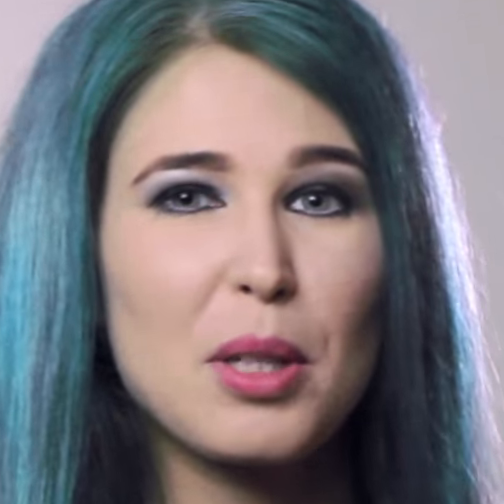

Split: LCC_FASD_training | Ficheiro: YOUTUBE_id57_s0_45.png | Resolução: 442x442


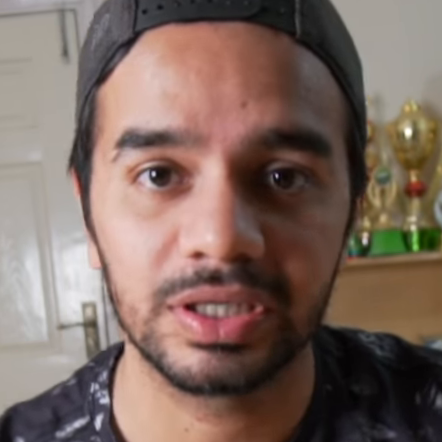

Split: LCC_FASD_training | Ficheiro: YOUTUBE_id88_s0_135.png | Resolução: 477x477


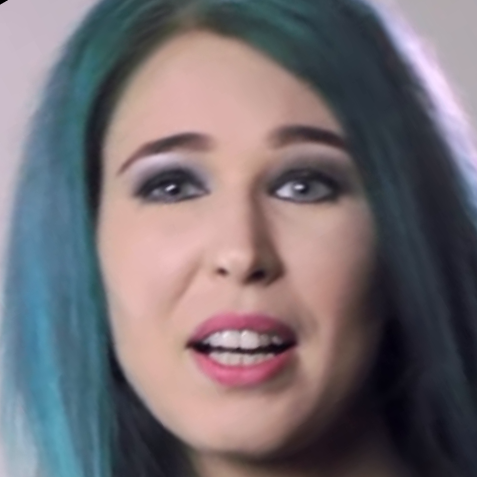


 SPOOF
Split: LCC_FASD_training | Ficheiro: YOUTUBE_S300U1A_HUAWEIY3II_id33_s2_45.png | Resolução: 624x624


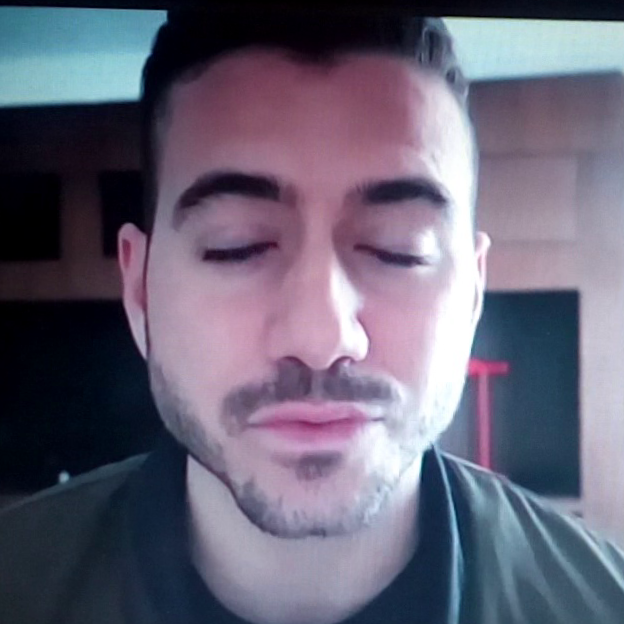

Split: LCC_FASD_evaluation | Ficheiro: spoof_5893.png | Resolução: 249x249


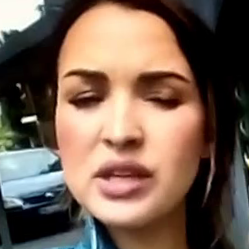

Split: LCC_FASD_development | Ficheiro: YOUTUBE_HP250_MEIZUM3S_id42_s0_30.png | Resolução: 541x541


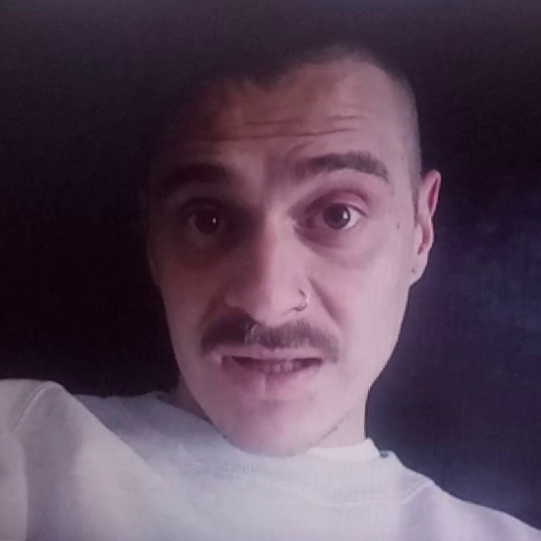

In [46]:
from IPython.display import display

for label in ["bona_fide", "spoof"]:

    samples = df[df["label"] == label].sample(3, random_state=1)

    print("\n", label.upper())

    for _, row in samples.iterrows():

        img = Image.open(row["filepath"]).convert("RGB")

        print(
            "Split:", row["split"],
            "| Ficheiro:", row["filename"],
            "| Resolução:", f"{row['width']}x{row['height']}"
        )

        display(img)

## 8. Resumo do dataset

In [48]:
summary = pd.DataFrame({
    "Parametro": [
        "Total de imagens",
        "Bona fide",
        "Spoof",
        "Training",
        "Development",
        "Evaluation",
        "Resoluções diferentes",
        "Largura mínima",
        "Largura máxima",
        "Altura mínima",
        "Altura máxima"
    ],
    "Valor": [
        len(df),
        (df["label"] == "bona_fide").sum(),
        (df["label"] == "spoof").sum(),
        (df["split"] == "LCC_FASD_training").sum(),
        (df["split"] == "LCC_FASD_development").sum(),
        (df["split"] == "LCC_FASD_evaluation").sum(),
        len(df[["width", "height"]].drop_duplicates()),
        df["width"].min(),
        df["width"].max(),
        df["height"].min(),
        df["height"].max()
    ]
})

summary

,Parametro,Valor
0,Total de imagens,18827
1,Bona fide,1942
2,Spoof,16885
3,Training,8299
4,Development,2948
5,Evaluation,7580
6,Resoluções diferentes,1132
7,Largura mínima,59
8,Largura máxima,2112
9,Altura mínima,59


## 9. Exportação dos resultados

O `DataFrame` final é guardado em CSV para permitir a comparação posterior com os restantes datasets analisados.

In [50]:
df.to_csv("results_datasets/lcc_fasd_dataset_report.csv", index=False)

print("Ficheiro criado: lcc_fasd_dataset_report.csv")

Ficheiro criado: lcc_fasd_dataset_report.csv


## Conclusão

O LCC-FASD contém **18 827 imagens**, distribuídas pelos conjuntos
`training`, `development` e `evaluation`.

Foram identificadas **1 942 imagens bona fide** e **16 885 imagens spoof**,
correspondendo aproximadamente a **10,31%** e **89,69%** do dataset,
respetivamente. Existe, portanto, um forte desequilíbrio entre as duas classes.

O dataset apresenta uma elevada diversidade de resoluções, com **1 132
resoluções diferentes**, variando entre **59x59** e **2112x2112 píxeis**.
Esta diversidade pode ser relevante para avaliar a robustez dos modelos
perante diferentes qualidades e condições de aquisição.

Alguns nomes de ficheiros contêm informação adicional relacionada com
sujeitos e dispositivos. No entanto, esta informação não está codificada de
forma uniforme em todos os splits, pelo que não foi utilizada como metadata
principal nesta primeira análise.

A diversidade de dispositivos e resoluções torna o LCC-FASD interessante
para experiências de robustez e generalização. Contudo, o forte desequilíbrio
entre classes exige cuidado na avaliação dos modelos, não sendo a `accuracy`
isoladamente uma métrica adequada.

O LCC-FASD será, por isso, considerado principalmente como dataset auxiliar,
enquanto datasets pertencentes aos protocolos clássicos de avaliação
cross-domain serão mais adequados para o benchmark principal da dissertação.